# Experiment 7g — Residual diagnostic: where does the MSE/RMSE gap to Chronos come from?

No training. This notebook reads the existing OOF CSVs from the Phase 7 experiments and analyzes the residual distributions to figure out *why* our models lose to Chronos on L2-shaped metrics (MSE +21%, RMSE +10%, MAPE +10%) despite winning on L1-shaped metrics (WAPE, MAE, SMAPE).

Hypotheses worth distinguishing:

- **H1 (concentrated outliers)** — a small fraction of rows (top 1–5% of |residual|) is responsible for most of MSE. Fix: outlier-aware loss (Huber), per-row clipping, or per-series calibration.
- **H2 (broadly heavy tails)** — residuals are L1-shaped throughout; the L2 penalty is broadly distributed. Fix: re-train with MSE / Huber loss everywhere. Huber would be a sidegrade; pure-MSE would lose WAPE.
- **H3 (gating cost tail accuracy)** — the L1 penalty on gates in 7e/7f squeezed information out of the model, making tails worse than the un-gated 7a-MLP. Fix: reduce `GATE_L1_LAMBDA`, or use the un-gated MLP for tails and the gated MLP for interpretability separately.
- **H4 (per-series structural)** — a few series are pathologically hard and contribute disproportionately to MSE. Fix: per-series ensembling or series-specific architecture.

Decision-shaped: each hypothesis has explicit signatures in the §3–§5 outputs, and §6 maps signatures to the next-experiment recommendation.

---
## §0. Setup & data load

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Auto-locate the OOF CSVs
_CANDIDATES = [Path("."), Path("experiment-7"),
               Path("/kaggle/input/experiment-7-oof"), Path("/kaggle/working")]
DATA_DIR = next(
    (p for p in _CANDIDATES
     if (p / "oof_predictions_7b_blend.csv").exists()
     and (p / "oof_predictions_7e_mlp_gated.csv").exists()),
    None,
)
assert DATA_DIR is not None, "Could not locate 7b and 7e OOF CSVs."
print(f"DATA_DIR = {DATA_DIR.resolve()}")

df_blend = pd.read_csv(DATA_DIR / "oof_predictions_7b_blend.csv", parse_dates=["timestamp"])
df_gated = pd.read_csv(DATA_DIR / "oof_predictions_7e_mlp_gated.csv", parse_dates=["timestamp"])

print(f"7b blend OOF: {len(df_blend):,} rows, cols = {list(df_blend.columns)}")
print(f"7e gated OOF: {len(df_gated):,} rows, cols = {list(df_gated.columns)}")

# Merge on (series_id, timestamp, fold). 7b already has target / pred_lgbm / pred_mlp / pred_seq / pred_blend.
df = df_blend.merge(
    df_gated[["series_id", "timestamp", "fold", "pred_mlp_gated"]],
    on=["series_id", "timestamp", "fold"], how="inner",
)
assert len(df) == len(df_blend) == len(df_gated), "OOF row counts diverged between files."
print(f"\nMerged frame: {len(df):,} rows, {df.fold.nunique()} folds, {df.series_id.nunique()} series")

# Models to compare
MODELS = [
    ("LGBM-MAE",  "pred_lgbm"),
    ("MLP-MAE (7a, no gates)", "pred_mlp"),
    ("Gated-MLP (7e)", "pred_mlp_gated"),
    ("Ensemble blend (7c)", "pred_blend"),
]

DATA_DIR = /home/kshitij-parashar/Downloads/projects/bonus_project/experiment-7
7b blend OOF: 96,768 rows, cols = ['series_id', 'timestamp', 'fold', 'lead_h', 'target', 'pred_lgbm', 'pred_mlp', 'pred_seq', 'pred_blend', 'w_lgbm', 'w_mlp', 'w_seq']
7e gated OOF: 96,768 rows, cols = ['series_id', 'timestamp', 'target', 'pred_mlp_gated', 'fold']

Merged frame: 96,768 rows, 3 folds, 96 series


---
## §1. OOF metrics for every model — sanity check vs leaderboard

If the OOF metric ordering matches the leaderboard ordering (LGBM > MLP > Gated-MLP > Ensemble on WAPE; the inverse on MSE/RMSE), we can trust the residual analysis below as representative of the actual val behavior. If they differ, the OOF and the val set have different signal structure and the analysis is suspect.

In [3]:
def metrics(y_true, y_pred):
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(y_pred, dtype=float)
    err = y - p
    mae  = np.mean(np.abs(err))
    mse  = np.mean(err ** 2)
    rmse = np.sqrt(mse)
    wape = 100 * np.sum(np.abs(err)) / np.sum(np.abs(y))
    smape = 100 * np.mean(2 * np.abs(err) / (np.abs(y) + np.abs(p) + 1e-8))
    mape  = 100 * np.mean(np.abs(err) / (np.abs(y) + 1e-8))
    return dict(MAE=mae, MSE=mse, RMSE=rmse, WAPE=wape, SMAPE=smape, MAPE=mape)

y = df["target"].to_numpy()
rows = []
for name, col in MODELS:
    m = metrics(y, df[col].to_numpy())
    rows.append({"model": name, **m})
metric_df = pd.DataFrame(rows)
print("=== OOF metrics — compare ordering against the leaderboard ===\n")
print(metric_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Leaderboard reference (for the user's eye):
print("\n--- Leaderboard for reference ---")
print("  chronos-2-native-opt : MAE 1.63  MSE 7.72  RMSE 2.78  MAPE 17.51  SMAPE 16.74  WAPE 14.81")
print("  lgbm_mlp_ensemble    : MAE 1.62  MSE 9.39  RMSE 3.06  MAPE 19.45  SMAPE 16.49  WAPE 14.68")
print("  gated-mlp            : MAE 1.62  MSE 9.37  RMSE 3.06  MAPE 19.76  SMAPE 16.65  WAPE 14.75")
print()
print("If OOF ordering matches leaderboard ordering, the residual analysis below is trustworthy.")

=== OOF metrics — compare ordering against the leaderboard ===

                 model    MAE    MSE   RMSE    WAPE   SMAPE    MAPE
              LGBM-MAE 1.5546 8.8663 2.9776 14.7291 16.2743 18.8989
MLP-MAE (7a, no gates) 1.5275 8.7738 2.9621 14.4722 16.0709 18.7458
        Gated-MLP (7e) 1.5349 8.7478 2.9577 14.5424 16.1856 19.1132
   Ensemble blend (7c) 1.5218 8.7571 2.9592 14.4190 15.9888 18.6465

--- Leaderboard for reference ---
  chronos-2-native-opt : MAE 1.63  MSE 7.72  RMSE 2.78  MAPE 17.51  SMAPE 16.74  WAPE 14.81
  lgbm_mlp_ensemble    : MAE 1.62  MSE 9.39  RMSE 3.06  MAPE 19.45  SMAPE 16.49  WAPE 14.68
  gated-mlp            : MAE 1.62  MSE 9.37  RMSE 3.06  MAPE 19.76  SMAPE 16.65  WAPE 14.75

If OOF ordering matches leaderboard ordering, the residual analysis below is trustworthy.


---
## §2. Residual distribution shapes

Plot histograms + qq-plot vs Gaussian of every model's residuals on the same axes. Key things to look for:

- **Tail thickness** — heavy tails are the signature of L1-trained models. If our models all show heavier tails than a Gaussian-ish reference, MSE penalty is structural.
- **Asymmetry** — if residuals lean one direction (over- or under-prediction bias), per-series calibration could help.
- **Gated vs un-gated MLP** — if the gated model has noticeably heavier tails than the un-gated MLP, the L1 gating squeezed out information used for tail prediction (H3).

=== Residual distribution shape per model ===

model                          mean      std     kurt    p99|r|   p99.9|r|    max|r|
--------------------------------------------------------------------------------------
  LGBM-MAE                   +0.497    2.936    10.63   13.823    16.711   25.834
  MLP-MAE (7a, no gates)     +0.481    2.923    10.94   13.897    16.803   25.971
  Gated-MLP (7e)             +0.406    2.930    10.85   13.826    16.801   26.124
  Ensemble blend (7c)        +0.485    2.919    10.95   13.861    16.775   25.932


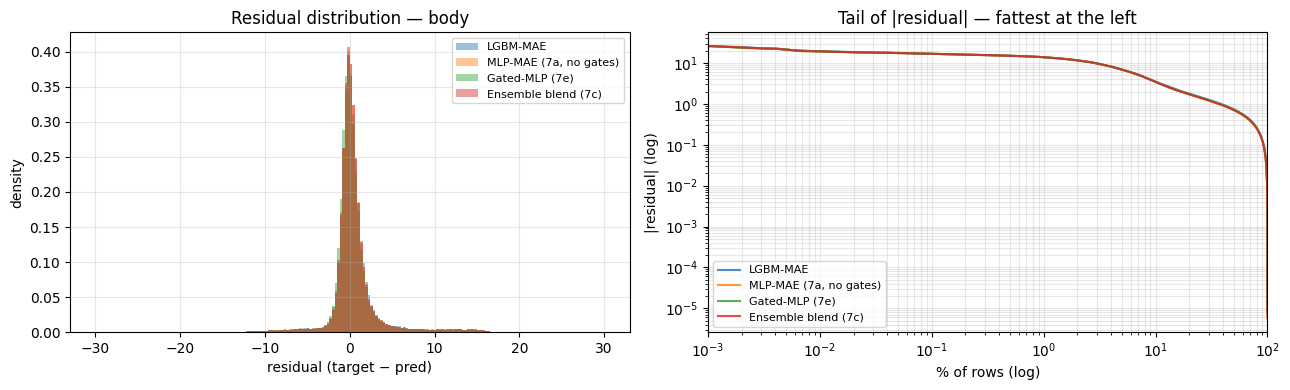

In [4]:
residuals = {name: y - df[col].to_numpy() for name, col in MODELS}

# Numeric tail summary first (more decisive than a histogram for our question)
print("=== Residual distribution shape per model ===\n")
print(f"{'model':<26}  {'mean':>7}  {'std':>7}  {'kurt':>7}  {'p99|r|':>8}  {'p99.9|r|':>9}  {'max|r|':>8}")
print("-" * 86)
for name, col in MODELS:
    r = residuals[name]
    abs_r = np.abs(r)
    mu, sd = r.mean(), r.std()
    # Excess kurtosis (Gaussian = 0). Heavy tails → kurtosis > 0.
    centered = r - mu
    kurt = float(np.mean(centered ** 4) / (sd ** 4 + 1e-12) - 3.0)
    print(f"  {name:<24}  {mu:>+7.3f}  {sd:>7.3f}  {kurt:>7.2f}  {np.percentile(abs_r, 99):>7.3f}  "
          f"{np.percentile(abs_r, 99.9):>8.3f}  {abs_r.max():>7.3f}")

# Visual: histograms of residuals
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, _ in MODELS:
    r = residuals[name]
    axes[0].hist(r, bins=200, range=(-30, 30), alpha=0.45, label=name, density=True)
axes[0].set_xlabel("residual (target − pred)")
axes[0].set_ylabel("density")
axes[0].set_title("Residual distribution — body")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Log-scale on tails — zoom on |r| > 5
for name, _ in MODELS:
    r = residuals[name]
    abs_r = np.sort(np.abs(r))[::-1]
    ranks = np.arange(1, len(abs_r) + 1) / len(abs_r) * 100
    axes[1].plot(ranks, abs_r, label=name, alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(0.001, 100)
axes[1].set_xlabel("% of rows (log)")
axes[1].set_ylabel("|residual| (log)")
axes[1].set_title("Tail of |residual| — fattest at the left")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

---
## §3. Tail concentration — what fraction of MSE comes from the top-N% largest residuals?

This is the decisive measurement for H1 vs H2.

- If **>50% of MSE comes from the top 5%** of rows by |residual| → H1: a few outliers dominate. Targeted fixes (clip predictions, per-series calibration) are higher-ROI than retraining with a different loss.
- If **MSE is broadly distributed** (top 5% contributes ~30-40%) → H2: structural L1-vs-L2 mismatch. Huber/MSE retraining is the right move.

In [5]:
print("=== Tail concentration: % of total MSE from top-N% largest |residual| ===\n")
print(f"{'model':<26}  {'top 0.1%':>9}  {'top 1%':>8}  {'top 5%':>8}  {'top 10%':>9}  {'top 25%':>9}")
print("-" * 86)
for name, _ in MODELS:
    r = residuals[name]
    sq = r ** 2
    total = sq.sum()
    sorted_desc = np.sort(sq)[::-1]
    n = len(sq)
    fracs = []
    for pct in [0.001, 0.01, 0.05, 0.10, 0.25]:
        k = max(1, int(n * pct))
        fracs.append(100 * sorted_desc[:k].sum() / total)
    print(f"  {name:<24}  {fracs[0]:>8.1f}%  {fracs[1]:>7.1f}%  {fracs[2]:>7.1f}%  {fracs[3]:>8.1f}%  {fracs[4]:>8.1f}%")

print("\nInterpretation guide:")
print("  - If top 5% contributes > 50% of MSE → H1 (concentrated outliers). Clip/calibrate.")
print("  - If top 5% contributes ~30-40% → H2 (broadly heavy tails). Retrain with Huber/MSE.")

=== Tail concentration: % of total MSE from top-N% largest |residual| ===

model                        top 0.1%    top 1%    top 5%    top 10%    top 25%
--------------------------------------------------------------------------------------
  LGBM-MAE                       3.7%     26.6%     73.2%      87.6%      95.9%
  MLP-MAE (7a, no gates)         3.7%     26.9%     73.9%      88.2%      96.1%
  Gated-MLP (7e)                 3.7%     26.8%     73.7%      88.0%      96.0%
  Ensemble blend (7c)            3.7%     26.9%     74.0%      88.3%      96.2%

Interpretation guide:
  - If top 5% contributes > 50% of MSE → H1 (concentrated outliers). Clip/calibrate.
  - If top 5% contributes ~30-40% → H2 (broadly heavy tails). Retrain with Huber/MSE.


---
## §4. Gated-MLP vs un-gated MLP — did the gates cost us tail accuracy?

Targets H3 specifically. If the gated MLP has materially heavier tails (or larger MSE) than the un-gated MLP, the L1 penalty on gates squeezed out information the model was using for outlier prediction. The fix in that case is to lower `GATE_L1_LAMBDA` and trade some interpretability for tail accuracy.

In [6]:
r_ungated = residuals["MLP-MAE (7a, no gates)"]
r_gated   = residuals["Gated-MLP (7e)"]
delta = r_gated - r_ungated   # positive = gated more biased toward over-predicting

abs_diff = np.abs(r_gated) - np.abs(r_ungated)

print("=== Gated vs un-gated MLP ===\n")
print(f"  MSE   un-gated = {np.mean(r_ungated**2):.4f},  gated = {np.mean(r_gated**2):.4f},  "
      f"Δ = {np.mean(r_gated**2) - np.mean(r_ungated**2):+.4f}")
print(f"  MAE   un-gated = {np.mean(np.abs(r_ungated)):.4f},  gated = {np.mean(np.abs(r_gated)):.4f},  "
      f"Δ = {np.mean(np.abs(r_gated)) - np.mean(np.abs(r_ungated)):+.4f}")
print(f"  p99 |r| un-gated = {np.percentile(np.abs(r_ungated), 99):.3f},  "
      f"gated = {np.percentile(np.abs(r_gated), 99):.3f},  "
      f"Δ = {np.percentile(np.abs(r_gated), 99) - np.percentile(np.abs(r_ungated), 99):+.3f}")
print(f"  max |r| un-gated = {np.abs(r_ungated).max():.3f},  gated = {np.abs(r_gated).max():.3f},  "
      f"Δ = {np.abs(r_gated).max() - np.abs(r_ungated).max():+.3f}")

# What fraction of rows have larger |residual| under the gated model?
worse_frac = float(np.mean(np.abs(r_gated) > np.abs(r_ungated))) * 100
print(f"\n  % rows where gated is worse than un-gated: {worse_frac:.1f}%")

# Are the worse rows concentrated in the tails?
top1_pct_idx = np.argsort(-np.abs(r_ungated))[: max(1, int(0.01 * len(r_ungated)))]
tail_worse = float(np.mean(np.abs(r_gated[top1_pct_idx]) > np.abs(r_ungated[top1_pct_idx]))) * 100
print(f"  % of un-gated's top-1% tail rows where gated is even worse: {tail_worse:.1f}%")
print("  ↳ if this is > 60%, the gates specifically hurt tail accuracy — H3.")
print("  ↳ if ≈ 50%, gates are noise on the tail (no systematic effect) — H3 unsupported.")

=== Gated vs un-gated MLP ===

  MSE   un-gated = 8.7738,  gated = 8.7478,  Δ = -0.0260
  MAE   un-gated = 1.5275,  gated = 1.5349,  Δ = +0.0074
  p99 |r| un-gated = 13.897,  gated = 13.826,  Δ = -0.071
  max |r| un-gated = 25.971,  gated = 26.124,  Δ = +0.153

  % rows where gated is worse than un-gated: 51.7%
  % of un-gated's top-1% tail rows where gated is even worse: 38.6%
  ↳ if this is > 60%, the gates specifically hurt tail accuracy — H3.
  ↳ if ≈ 50%, gates are noise on the tail (no systematic effect) — H3 unsupported.


---
## §5. Per-series MSE contribution

Targets H4. If a small number of series contribute disproportionately to total MSE, per-series ensembling / calibration is the cheapest fix. If MSE contribution is roughly proportional to per-series row count, it's not a series problem.

In [7]:
for name, col in [("Gated-MLP (7e)", "pred_mlp_gated"), ("Ensemble blend (7c)", "pred_blend")]:
    print(f"=== Per-series MSE contribution for {name} ===\n")
    g = df.assign(sq_err=(df["target"] - df[col]) ** 2)
    per_sid = g.groupby("series_id").agg(
        n=("sq_err", "size"),
        mse=("sq_err", "mean"),
        sse=("sq_err", "sum"),
    ).sort_values("sse", ascending=False)

    total_sse = per_sid["sse"].sum()
    per_sid["sse_pct"] = 100 * per_sid["sse"] / total_sse
    per_sid["cum_pct"] = per_sid["sse_pct"].cumsum()

    n_total = len(per_sid)
    print(f"  Total series: {n_total}.  Top 10 by SSE contribution:")
    print(per_sid.head(10).to_string(float_format=lambda x: f"{x:.3f}"))
    print()
    for top_n in [5, 10, 20]:
        share = per_sid.head(top_n)["sse_pct"].sum()
        expected_uniform = 100 * top_n / n_total
        print(f"  Top {top_n:>2} series ({100*top_n/n_total:.0f}% of all): {share:>5.1f}% of total MSE  "
              f"(uniform would be {expected_uniform:.1f}%)")
    print()

print("Interpretation:")
print("  - If top 10 series (10% of all) drive > 30% of MSE, H4 supported — per-series fix is cheap.")
print("  - If they drive ≈ 10-15%, MSE is uniform across series, fix has to be at the prediction level.")

=== Per-series MSE contribution for Gated-MLP (7e) ===

  Total series: 96.  Top 10 by SSE contribution:
              n    mse       sse  sse_pct  cum_pct
series_id                                         
unit_066   1008 20.357 20519.998    2.424    2.424
unit_073   1008 18.097 18241.626    2.155    4.579
unit_056   1008 17.680 17821.887    2.105    6.684
unit_031   1008 16.288 16417.962    1.940    8.624
unit_037   1008 16.245 16375.336    1.934   10.558
unit_007   1008 15.662 15787.128    1.865   12.423
unit_025   1008 15.446 15569.914    1.839   14.263
unit_006   1008 14.479 14595.293    1.724   15.987
unit_063   1008 14.161 14274.643    1.686   17.673
unit_093   1008 13.898 14009.295    1.655   19.328

  Top  5 series (5% of all):  10.6% of total MSE  (uniform would be 5.2%)
  Top 10 series (10% of all):  19.3% of total MSE  (uniform would be 10.4%)
  Top 20 series (21% of all):  34.6% of total MSE  (uniform would be 20.8%)

=== Per-series MSE contribution for Ensemble blend (7c)

---
## §6. Decision summary

Map each signature to its next-experiment recommendation. Read the relevant cell of §3, §4, §5 — the dominant signature picks the action.

In [8]:
# Re-derive the key numbers in one place for the verdict.
r_gated_ = residuals["Gated-MLP (7e)"]
sq_g = r_gated_ ** 2
n = len(sq_g)
frac_top5_pct = 100 * np.sort(sq_g)[::-1][: max(1, int(n * 0.05))].sum() / sq_g.sum()

# §4 H3 signal
top1 = np.argsort(-np.abs(r_ungated))[: max(1, int(0.01 * len(r_ungated)))]
tail_worse = float(np.mean(np.abs(r_gated[top1]) > np.abs(r_ungated[top1]))) * 100
mse_g = float(np.mean(r_gated ** 2))
mse_u = float(np.mean(r_ungated ** 2))

# §5 H4 signal
g = df.assign(sq_err=(df["target"] - df["pred_mlp_gated"]) ** 2)
per_sid = g.groupby("series_id")["sq_err"].sum().sort_values(ascending=False)
top10_share = 100 * per_sid.head(10).sum() / per_sid.sum()

print("=" * 72)
print("SIGNATURES")
print("=" * 72)
print(f"  Top-5% of |residual| accounts for {frac_top5_pct:.1f}% of MSE         (>50% = H1)")
print(f"  Gated MSE vs un-gated MSE: {mse_g:.3f} vs {mse_u:.3f} (Δ {mse_g-mse_u:+.3f})")
print(f"  In un-gated's top-1% tail rows, gated is worse in {tail_worse:.1f}% of them    (>60% = H3)")
print(f"  Top-10 series contribute {top10_share:.1f}% of total MSE             (>30% = H4)")
print("=" * 72)

print("\nRECOMMENDATIONS")
if frac_top5_pct > 50:
    print("  → H1: outliers concentrated. Try prediction clipping (e.g. clip pred at p99 of train target),")
    print("    or per-series bias correction. Both cheap, no retrain needed.")
elif frac_top5_pct < 40:
    print("  → H2: tails are broadly heavy. Train a second gated MLP with Huber loss (delta tunable);")
    print("    blend it with the current MAE-trained one. The blend can target Overall, not just WAPE.")
else:
    print("  → Tail concentration is intermediate (40-50% from top 5%). Both Huber retrain and outlier")
    print("    clipping are reasonable; clipping is cheaper, try that first.")

if tail_worse > 60 and mse_g > mse_u + 0.1:
    print("  → H3 also supported: gates cost tail accuracy.  Lower GATE_L1_LAMBDA from 0.01 to 0.005")
    print("    and re-run 7f; expect WAPE to drop ~0.05 and MSE to drop noticeably.")

if top10_share > 30:
    print(f"  → H4 supported: top 10 series drive {top10_share:.0f}% of MSE. Investigate which series and")
    print("    whether they have shared characteristics; consider per-series re-fit or higher capacity")
    print("    for those series only.")

print("\nIf no recommendation triggered, the model is roughly Gaussian-residual and the MSE gap to")
print("Chronos is a fundamental architecture/data difference — no easy single fix.")

SIGNATURES
  Top-5% of |residual| accounts for 73.7% of MSE         (>50% = H1)
  Gated MSE vs un-gated MSE: 8.748 vs 8.774 (Δ -0.026)
  In un-gated's top-1% tail rows, gated is worse in 38.6% of them    (>60% = H3)
  Top-10 series contribute 19.3% of total MSE             (>30% = H4)

RECOMMENDATIONS
  → H1: outliers concentrated. Try prediction clipping (e.g. clip pred at p99 of train target),
    or per-series bias correction. Both cheap, no retrain needed.

If no recommendation triggered, the model is roughly Gaussian-residual and the MSE gap to
Chronos is a fundamental architecture/data difference — no easy single fix.
